# UK Turnout Analysis Project

## NB04: Regression Analysis

This notebook models constituency-level turnout at the 2024 general election using the demographic and socioeconomic predictors constructed in NB02.

Analysis begins with a naive multivariate OLS model to provide an easily-interpretable baseline. Model diagnostics are then used to assess observed multicollinearity, suspected heteroskedasticity, functional form and influential observations before alternative specifications are considered.

These results describe constituency-level associations and should not be interpreted as individual-level or causal effects.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
import statsmodels.api as sm


In [2]:
data = pd.read_csv("../data/processed/analysis_data.csv")

assert len(data) == 575
assert data["constituency_code"].is_unique
assert data.notna().all().all()

data["log_population_density"] = np.log(
    data["population_density"]
)

In [3]:
predictors = [
    "level4_plus_pct",
    "age_18_34_pct",
    "age_65_plus_pct",
    "owner_occupied_pct",
    "social_rented_pct",
    "unemployment_rate",
    "log_population_density"
]

### 1. Baseline OLS model

The baseline specification includes all seven predictors identified before modelling. Although exploratory analysis showed substantial correlation among several predictors, they are initially retained so that multicollinearity can be assessed before considering removing variables on the basis of pairwise correlation.

In [4]:
formula = (
    "turnout_pct ~ "
    + " + ".join(predictors)
)

baseline_model = smf.ols(
    formula,
    data=data
).fit()

baseline_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            turnout_pct   R-squared:                       0.809
Model:                            OLS   Adj. R-squared:                  0.806
Method:                 Least Squares   F-statistic:                     342.0
Date:                Wed, 14 Oct 2026   Prob (F-statistic):          7.45e-199
Time:                        14:52:12   Log-Likelihood:                -1459.9
No. Observations:                 575   AIC:                             2936.
Df Residuals:                     567   BIC:                             2971.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 35.9554      4.593      7.829      0.000      26.935      44.976
level4_plus_pct            0.4886      0.019     26.303      0.000       0.452       0.525
age_18_34_pct              0.0351      0.044      0.794      0.427      -0.052       0.122
age_65_plus_pct            0.2257      0.053      4.224      0.000       0.121       0.331
owner_occupied_pct         0.1682      0.035      4.866      0.000       0.100       0.236
social_rented_pct         -0.1362      0.038     -3.630      0.000      -0.210      -0.062
unemployment_rate         -0.7581      0.137     -5.522      0.000      -1.028      -0.488
log_population_density    -0.3854      0.164     -2.344      0.019      -0.708      -0.062
==============================================================================
Omnibus:                       43.850   Durbin-Watson:                   1.696
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              110.212
Skew:                          -0.387   Prob(JB):                     1.17e-24
Kurtosis:                       5.000   Cond. No.                     2.95e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.95e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

#### Baseline model results

The naive model explains ~81% of the variation in constituency turnout. Educational attainment, population share aged 65 and over, and owner occupation are positively associated with turnout, while social renting, unemployment and population density show negative association with turnout.

The biggest change compared to the bivariate analysis involved population share aged 18–34. While younger constituencies display substantially lower turnout in the raw data, this association becomes small and statistically insignificant (p=0.427) once the other predictors are included. This is consistent with strong pairwise correlations observed between age structure, housing tenure, unemployment and population density im NB03.

These coefficients are conditional associations rather than causal effects, and the strong correlations among predictors require further multicollinearity diagnostics before the coefficients are interpreted more substantively.

#### Multicollinearity Diagnostics

In [6]:
X = sm.add_constant(data[predictors])

vif = pd.DataFrame({
    "variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

vif = vif[vif["variable"] != "const"]

vif.sort_values("VIF", ascending=False)

,variable,VIF
4,owner_occupied_pct,9.850287
3,age_65_plus_pct,7.017139
2,age_18_34_pct,6.562311
6,unemployment_rate,4.327910
5,social_rented_pct,3.972289
7,log_population_density,3.371889
1,level4_plus_pct,1.691469


Variance inflation factors confirm substantial overlap between a group of predictors.

Owner occupation has the highest VIF (~9.9), and both age structure measures have VIFs >6. These results are consistent with the earlier correlation analysis: older constituencies tend to have higher owner-occupation rates, while younger constituencies tend to be more densely populated, have higher unemployment, and contain more rented housing.

Educational attainment displays relatively little collinearity with the other predictors.

These VIFs indicate that some coefficients in the full specification may be unstable.  Reduced specifications will thus be compared to assess whether removing severely collinear predictors can stabilise these coefficients without substantially reducing model fit.

In [7]:
reduced_predictors = [
    "level4_plus_pct",
    "age_65_plus_pct",
    "owner_occupied_pct",
    "social_rented_pct",
    "unemployment_rate",
    "log_population_density"
]

reduced_formula = (
    "turnout_pct ~ "
    + " + ".join(reduced_predictors)
)

reduced_model = smf.ols(
    reduced_formula,
    data=data
).fit()

reduced_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            turnout_pct   R-squared:                       0.808
Model:                            OLS   Adj. R-squared:                  0.806
Method:                 Least Squares   F-statistic:                     399.2
Date:                Wed, 14 Oct 2026   Prob (F-statistic):          4.89e-200
Time:                        15:06:09   Log-Likelihood:                -1460.2
No. Observations:                 575   AIC:                             2934.
Df Residuals:                     568   BIC:                             2965.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 38.2863      3.531     10.842      0.000      31.350      45.222
level4_plus_pct            0.4887      0.019     26.317      0.000       0.452       0.525
age_65_plus_pct            0.2014      0.044      4.601      0.000       0.115       0.287
owner_occupied_pct         0.1577      0.032      4.941      0.000       0.095       0.220
social_rented_pct         -0.1432      0.036     -3.928      0.000      -0.215      -0.072
unemployment_rate         -0.7362      0.134     -5.476      0.000      -1.000      -0.472
log_population_density    -0.4061      0.162     -2.502      0.013      -0.725      -0.087
==============================================================================
Omnibus:                       43.189   Durbin-Watson:                   1.699
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              111.107
Skew:                          -0.372   Prob(JB):                     7.47e-25
Kurtosis:                       5.021   Cond. No.                     2.15e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.15e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [8]:
X_reduced = sm.add_constant(
    data[reduced_predictors]
)

vif_reduced = pd.DataFrame({
    "variable": X_reduced.columns,
    "VIF": [
        variance_inflation_factor(X_reduced.values, i)
        for i in range(X_reduced.shape[1])
    ]
})

vif_reduced = vif_reduced[
    vif_reduced["variable"] != "const"
]

vif_reduced.sort_values("VIF", ascending=False)

,variable,VIF
3,owner_occupied_pct,8.398985
2,age_65_plus_pct,4.711540
5,unemployment_rate,4.153457
4,social_rented_pct,3.752559
6,log_population_density,3.287003
1,level4_plus_pct,1.691400


In [9]:
pd.DataFrame({
    "Full model": [
        baseline_model.rsquared_adj,
        baseline_model.aic,
        baseline_model.bic
    ],
    "Reduced model": [
        reduced_model.rsquared_adj,
        reduced_model.aic,
        reduced_model.bic
    ]
}, index=[
    "Adjusted R²",
    "AIC",
    "BIC"
])

,Full model,Reduced model
Adjusted R²,0.806151,0.806277
AIC,2935.840460,2934.479785
BIC,2970.675420,2964.960376


#### Reduced baseline specification

Removing the share aged 18–34 has virtually no effect on model fit. R^2 is nearly identical (0.808 vs 0.809), while adjusted R^2 marginally increases and both AIC and BIC improve.

Multicollinearity also improves: VIF for the population share >=65 falls below 5, and the VIF for owner occupation declines. The remaining coefficient estimates are broadly stable.

This six-predictor specification is therefore used as the preferred linear baseline. Owner occupation continues to exhibit relatively high collinearity (VIF ~8.4), but it is retained at this stage because it represents a substantively distinct housing characteristic and its estimated coefficient is stable across the two specifications.

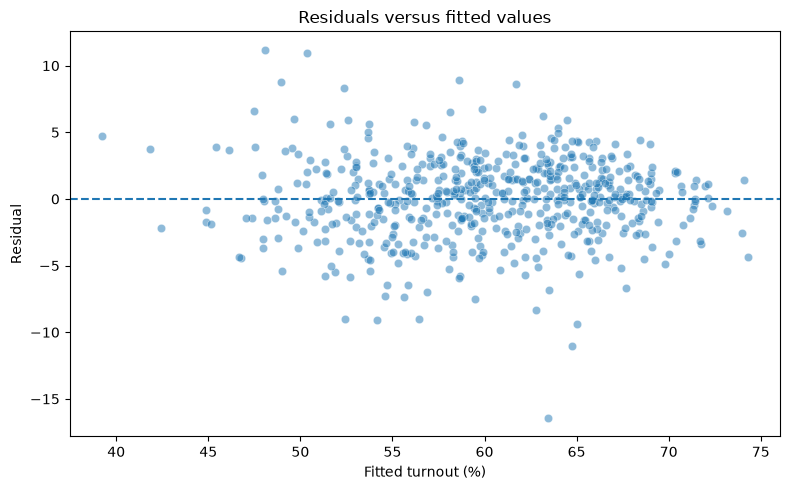

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    x=reduced_model.fittedvalues,
    y=reduced_model.resid,
    alpha=0.5,
    ax=ax
)

ax.axhline(0, linestyle="--")

ax.set_xlabel("Fitted turnout (%)")
ax.set_ylabel("Residual")
ax.set_title("Residuals versus fitted values")

plt.tight_layout()
plt.show()

In [11]:
bp_test = het_breuschpagan(
    reduced_model.resid,
    reduced_model.model.exog
)

bp_results = pd.Series(
    bp_test,
    index=[
        "LM statistic",
        "LM p-value",
        "F statistic",
        "F p-value"
    ]
)

bp_results

LM statistic    20.416109
LM p-value       0.002334
F statistic      3.485000
F p-value        0.002158
dtype: float64

In [12]:
reduced_model_hc3 = reduced_model.get_robustcov_results(
    cov_type="HC3"
)

reduced_model_hc3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            turnout_pct   R-squared:                       0.808
Model:                            OLS   Adj. R-squared:                  0.806
Method:                 Least Squares   F-statistic:                     380.3
Date:                Wed, 14 Oct 2026   Prob (F-statistic):          3.02e-195
Time:                        15:14:29   Log-Likelihood:                -1460.2
No. Observations:                 575   AIC:                             2934.
Df Residuals:                     568   BIC:                             2965.
Df Model:                           6                                         
Covariance Type:                  HC3                                         
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 38.2863      3.513     10.897      0.000      31.386      45.187
level4_plus_pct            0.4887      0.019     25.159      0.000       0.451       0.527
age_65_plus_pct            0.2014      0.042      4.840      0.000       0.120       0.283
owner_occupied_pct         0.1577      0.038      4.165      0.000       0.083       0.232
social_rented_pct         -0.1432      0.042     -3.447      0.001      -0.225      -0.062
unemployment_rate         -0.7362      0.154     -4.787      0.000      -1.038      -0.434
log_population_density    -0.4061      0.163     -2.494      0.013      -0.726      -0.086
==============================================================================
Omnibus:                       43.189   Durbin-Watson:                   1.699
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              111.107
Skew:                          -0.372   Prob(JB):                     7.47e-25
Kurtosis:                       5.021   Cond. No.                     2.15e+03
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
[2] The condition number is large, 2.15e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

#### Heteroskedasticity and robust inference

The residual-versus-fitted plot suggests variation in residual dispersion across fitted turnout values. The Breusch–Pagan test rejects the null hypothesis of homoskedastic errors at any conventional significance level (p = 0.002).

The preferred linear specification is therefore reported with HC3 heteroskedasticity-robust standard errors. Robust inference does not materially change the results: all six predictors remain statistically significant and their estimated coefficients are unchanged.

HC3 standard errors are used for subsequent inference from the linear model.

#### Influence diagnostics

Residual diagnostics indicate several unusually large errors. Influence statistics are therefore examined to determine whether any individual constituencies have disproportionate effects on coefficient estimates.

In [13]:
influence = reduced_model.get_influence()

influence_df = pd.DataFrame({
    "constituency_name": data["constituency_name"],
    "studentized_residual": influence.resid_studentized_external,
    "leverage": influence.hat_matrix_diag,
    "cooks_distance": influence.cooks_distance[0]
})

influence_df.nlargest(
    10, "cooks_distance"
)

,constituency_name,studentized_residual,leverage,cooks_distance
122,Cities of London and Westminster,-3.713136,0.048585,0.098366
259,Islington North,2.967087,0.034444,0.044257
264,Kensington and Bayswater,-2.764544,0.037456,0.041995
281,Leicester South,3.704852,0.019843,0.038826
36,Birmingham Ladywood,1.604818,0.086782,0.034866
26,Bethnal Green and Stepney,2.892719,0.027985,0.033976
73,Brighton Pavilion,2.837653,0.023534,0.027384
74,Bristol Central,2.054741,0.040600,0.025380
219,Hampstead and Highgate,-2.220889,0.034696,0.025152
159,Dwyfor Meirionnydd,-3.097864,0.017669,0.024291


In [14]:
influence_df[
    influence_df["studentized_residual"].abs() > 3
].sort_values(
    "studentized_residual",
    key=abs,
    ascending=False
)

,constituency_name,studentized_residual,leverage,cooks_distance
120,Chorley,-5.474537,0.004611,0.018873
122,Cities of London and Westminster,-3.713136,0.048585,0.098366
281,Leicester South,3.704852,0.019843,0.038826
280,Leicester East,3.616713,0.010981,0.020316
159,Dwyfor Meirionnydd,-3.097864,0.017669,0.024291


#### Influential observations

Some constituencies have unusually large residuals or high leverage, although the two do not always coincide.

Chorley has the largest studentized residual but low leverage, meaning that it is poorly predicted but does not have a particularly large effect on the fitted
model. Cities of London and Westminster combines a large residual with
relatively high leverage and consequently has the largest Cook's distance.

A number of observations exceed the conventional `4/n` Cook's-distance
screening threshold. This threshold is treated as a diagnostic flag rather than
as automatic ground for deleting observations. Observations are retained unless there is evidence of error, and the model's sensitivity to the most influential constituencies is assessed separately.

In [15]:
cooks_threshold = 4 / len(data)

flagged_influence = influence_df[
    influence_df["cooks_distance"] > cooks_threshold
].sort_values(
    "cooks_distance",
    ascending=False
)

print("Cook's distance threshold:", cooks_threshold)
print("Flagged constituencies:", len(flagged_influence))

flagged_influence

Cook's distance threshold: 0.006956521739130435
Flagged constituencies: 29


,constituency_name,studentized_residual,leverage,cooks_distance
122,Cities of London and Westminster,-3.713136,0.048585,0.098366
259,Islington North,2.967087,0.034444,0.044257
264,Kensington and Bayswater,-2.764544,0.037456,0.041995
281,Leicester South,3.704852,0.019843,0.038826
36,Birmingham Ladywood,1.604818,0.086782,0.034866
26,Bethnal Green and Stepney,2.892719,0.027985,0.033976
73,Brighton Pavilion,2.837653,0.023534,0.027384
74,Bristol Central,2.054741,0.040600,0.025380
219,Hampstead and Highgate,-2.220889,0.034696,0.025152
159,Dwyfor Meirionnydd,-3.097864,0.017669,0.024291


In [16]:
top_influential = (
    influence_df
    .nlargest(5, "cooks_distance")
    ["constituency_name"]
    .tolist()
)

sensitivity_data = data[
    ~data["constituency_name"].isin(top_influential)
].copy()

sensitivity_model = smf.ols(
    reduced_formula,
    data=sensitivity_data
).fit(cov_type="HC3")

sensitivity_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            turnout_pct   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.819
Method:                 Least Squares   F-statistic:                     423.4
Date:                Wed, 14 Oct 2026   Prob (F-statistic):          5.51e-205
Time:                        15:33:17   Log-Likelihood:                -1426.0
No. Observations:                 570   AIC:                             2866.
Df Residuals:                     563   BIC:                             2896.
Df Model:                           6                                         
Covariance Type:                  HC3                                         
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 40.2214      3.317     12.125      0.000      33.720      46.723
level4_plus_pct            0.4896      0.019     26.351      0.000       0.453       0.526
age_65_plus_pct            0.2272      0.038      6.011      0.000       0.153       0.301
owner_occupied_pct         0.1253      0.032      3.857      0.000       0.062       0.189
social_rented_pct         -0.1631      0.038     -4.266      0.000      -0.238      -0.088
unemployment_rate         -0.8811      0.145     -6.074      0.000      -1.165      -0.597
log_population_density    -0.3194      0.158     -2.020      0.043      -0.629      -0.009
==============================================================================
Omnibus:                       44.516   Durbin-Watson:                   1.729
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              104.977
Skew:                          -0.419   Prob(JB):                     1.60e-23
Kurtosis:                       4.928   Cond. No.                     2.16e+03
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
[2] The condition number is large, 2.16e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [17]:
coefficient_comparison = pd.DataFrame({
    "Preferred model": reduced_model_hc3.params,
    "Sensitivity model": sensitivity_model.params
})

coefficient_comparison["difference"] = (
    coefficient_comparison["Sensitivity model"]
    - coefficient_comparison["Preferred model"]
)

coefficient_comparison

,Preferred model,Sensitivity model,difference
Intercept,38.286337,40.221377,1.935040
level4_plus_pct,0.488671,0.489582,0.000911
age_65_plus_pct,0.201357,0.227234,0.025877
owner_occupied_pct,0.157664,0.125271,-0.032393
social_rented_pct,-0.143181,-0.163112,-0.019931
unemployment_rate,-0.736214,-0.881147,-0.144933
log_population_density,-0.406096,-0.319351,0.086745


In [18]:
preferred_params = pd.Series(
    reduced_model_hc3.params,
    index=reduced_model.params.index
)

coefficient_comparison = pd.DataFrame({
    "Preferred model": preferred_params,
    "Sensitivity model": sensitivity_model.params
})

coefficient_comparison["difference"] = (
    coefficient_comparison["Sensitivity model"]
    - coefficient_comparison["Preferred model"]
)